In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import os

import seaborn as sns

from scipy import sparse

import numpy as np, pandas as pd, seaborn as sns, matplotlib.pyplot as plt
from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import linkage, leaves_list

plt.rcParams.update({
    "axes.titlesize": 26,
    "axes.labelsize": 18,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
})

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
from pygam import LinearGAM, s
import pygam

In [2]:
mouse_base_path = '/n/eddy_lab/Lab/mckinley_backup_2025-12-18/data/'

mouse_h5ad_file = '2025_09_01_1_dpi_l+4_dpi_pseudotime.h5ad'
mouse_h5ad_path = os.path.join(mouse_base_path,mouse_h5ad_file)

human_base_path = '/n/eddy_lab/Lab/mckinley_backup_2025-12-18/data/'
human_h5ad_file = '2025_10_07_human_fibroblasts_pseudotime_submission.h5ad'
human_h5ad_path = os.path.join(human_base_path,human_h5ad_file)

mi_base_path = '.'
mi_genes_file = './human_mouse_mi.csv'
mi_genes_path = os.path.join(mi_base_path, mi_genes_file)

In [3]:
adata_mouse = sc.read_h5ad(mouse_h5ad_path)

In [4]:
adata_human = sc.read_h5ad(human_h5ad_path)

In [5]:
mi_genes = pd.read_csv(mi_genes_path,  index_col = 0)

In [ ]:
mouse_genes

In [10]:
print(mi_genes)

           mouse_gene top_10_pct_mi  human_mi_rank  mouse_mi_rank  \
human_gene                                                          
KCNIP4         Kcnip4         human            1.0         6237.0   
MMP10           Mmp10         human            2.0            NaN   
NEAT1           Neat1          both            3.0          407.0   
DIO2             Dio2         human            5.0         5257.0   
SOX4             Sox4         human            6.0         3250.0   
...               ...           ...            ...            ...   
ZP2               Zp2       neither            NaN            NaN   
ZPBP2           Zpbp2       neither            NaN            NaN   
ZSWIM1         Zswim1       neither            NaN        13601.0   
ZSWIM3         Zswim3       neither            NaN         9955.0   
ZWINT           Zwint         mouse            NaN         1423.0   

            human_mi_percentile  mouse_mi_percentile  human_mi  mouse_mi  \
human_gene                

In [11]:
mouse_genes = mi_genes.loc[
    mi_genes['top_10_pct_mi'].isin(['mouse', 'both']),
    'mouse_gene'
].tolist()

adata_mouse_mi = adata_mouse[:, mouse_genes].copy()

In [12]:
adata_mouse_mi = adata_mouse[:,mouse_genes].copy()

In [13]:
adata_mouse_mi

AnnData object with n_obs × n_vars = 15962 × 1263
    obs: 'cell_barcode', 'cellbender_filtered', 'day_pseudopregnancy', 'doubletdetection_doublet_score', 'doubletdetection_predicted_doublet', 'leiden_scVI_0.1', 'leiden_scVI_0.3', 'leiden_scVI_0.5', 'leiden_scVI_1.0', 'leiden_scVI_3.0', 'mck', 'n_counts', 'n_genes_by_counts', 'pct_counts_in_top_20_genes', 'pct_counts_intronic', 'pct_counts_mito', 'pct_counts_ribo', 'sample', 'species', 'timepoint', 'total_counts', 'total_counts_mito', 'total_counts_ribo', 'x_um', 'x_um_dbscan', 'y_um', 'y_um_dbscan', 'zeitgeber_time', 'leiden_scVI_0.2', 'leiden_scVI_0.4', 'leiden_scVI_0.6', 'leiden_scVI_0.7', 'leiden_scVI_0.8', 'leiden_scVI_0.9', 'leiden_scVI_1.5', 'leiden_scVI_2.0', 'leiden_scVI_2.5', 'cell_type_coarse', 'cell_type_fine', 'S_score', 'G2M_score', 'cluster_number', '_scvi_batch', '_scvi_labels', 'is_root', 'dpt_pseudotime'
    var: 'mito', 'ribo', 'highly_variable', 'highly_variable_rank', 'highly_variable_nbatches', 'means', 'variances

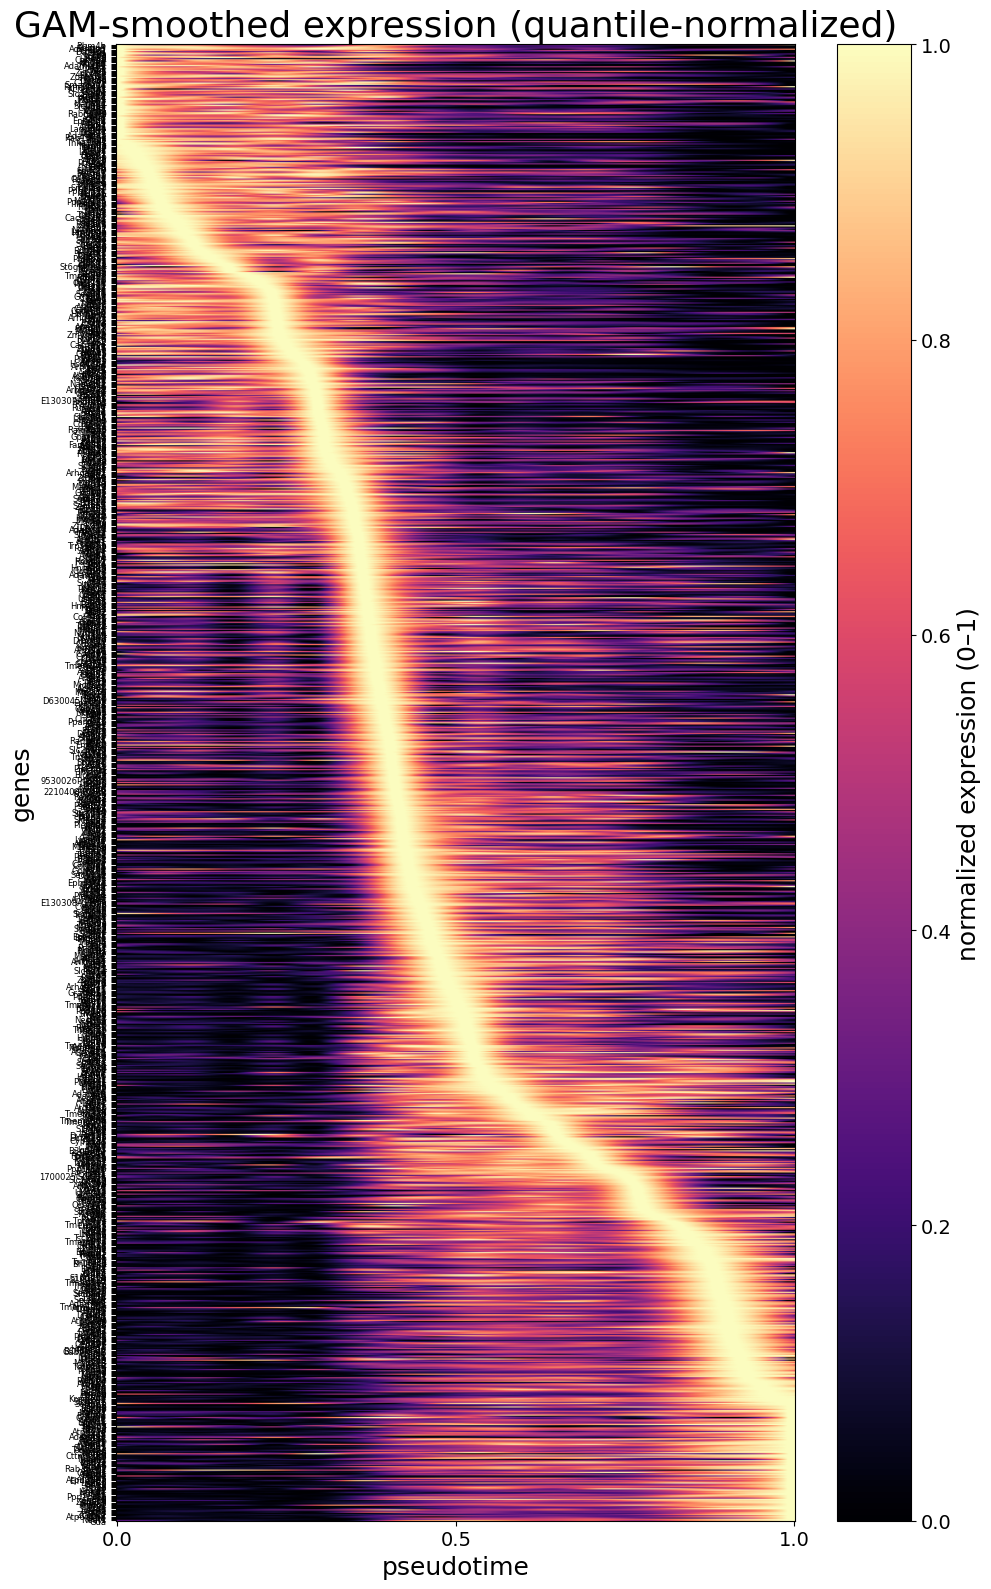

In [15]:
adata = adata_mouse_mi.copy()

# pull pseudotime + expression
pt = adata.obs["dpt_pseudotime"].astype(float).values
mask = np.isfinite(pt)
expr_df = sc.get.obs_df(adata[mask], keys=list(adata.var_names), layer="log1p")
expr_df["pseudotime"] = pt[mask]

pt_grid = np.linspace(expr_df["pseudotime"].min(), expr_df["pseudotime"].max(), 800)

# fit GAM for each gene
smoothed = {}
x = expr_df["pseudotime"].values
for gene in adata.var_names:
    y = expr_df[gene].values
    gam = LinearGAM(s(0, n_splines=20)).fit(x, y)
    smoothed[gene] = gam.predict(pt_grid)

heatmap_df = pd.DataFrame(smoothed, index=pt_grid).T  # genes by pseudotime grid

# quantile-normalize
low = heatmap_df.quantile(0.01, axis=1)
high = heatmap_df.quantile(0.99, axis=1)
robust = (
    heatmap_df
    .sub(low, axis=0)
    .div((high - low).replace(0, np.nan), axis=0)
    .clip(0, 1)
    .fillna(0)
)

# sort genes by peak pseudotime
peak_idx = robust.values.argmax(axis=1)
order = np.argsort(peak_idx)
robust = robust.iloc[order]

# plot arrays
norm_epxr = robust.values

# heatmap
plt.figure(figsize=(10, 16))
im = plt.imshow(
    norm_epxr,
    aspect="auto",
    interpolation="bilinear",
    cmap="magma",
    origin="upper"
)

plt.colorbar(im, label="normalized expression (0–1)")
plt.xlabel("pseudotime")
plt.ylabel("genes")
plt.title("GAM-smoothed expression (quantile-normalized)")

plt.yticks(range(len(robust)), robust.index, fontsize=6)
plt.xticks([0, int(norm_epxr.shape[1]/2), norm_epxr.shape[1]-1], ["0.0", "0.5", "1.0"])

plt.tight_layout()
plt.savefig("./mouse_pseudotime_heatmap.png", dpi=300,
            bbox_inches="tight")
plt.show()

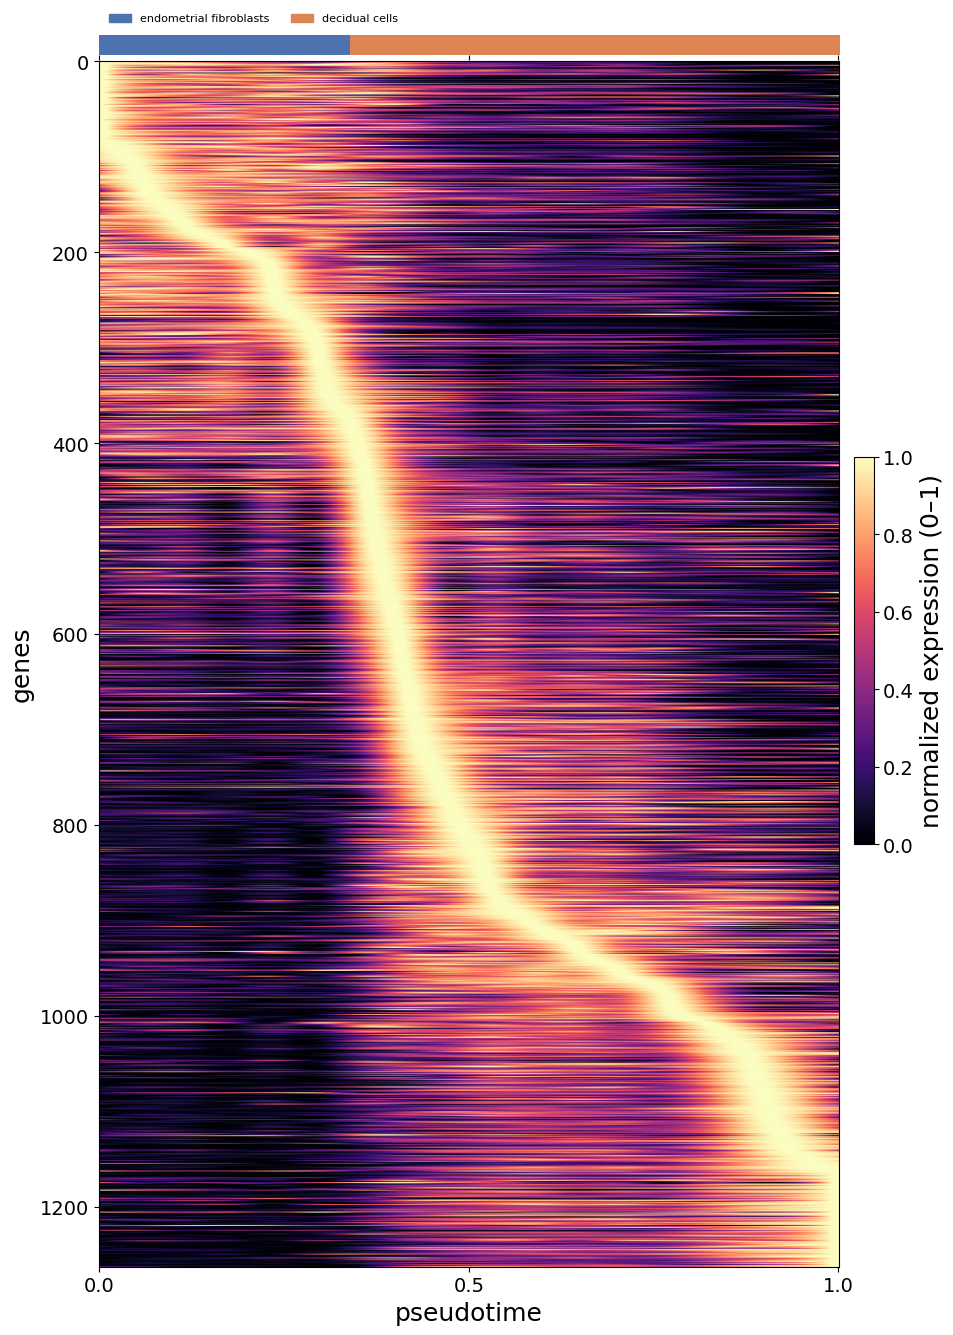

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# --- cell-identity band along pt_grid (reuses adata + pt_grid only) ---
cell_pt  = adata.obs["dpt_pseudotime"].astype(float).values
cell_lab = adata.obs["cell_type_coarse"].astype(str).values
ok = np.isfinite(cell_pt)
cell_pt, cell_lab = cell_pt[ok], cell_lab[ok]

is_dec = (cell_lab == "decidual cells").astype(float)   # 1=decidual, 0=fibroblast

sortk = np.argsort(cell_pt)
pt_s, dec_s = cell_pt[sortk], is_dec[sortk]
w = (pt_grid.max() - pt_grid.min()) / 50                # window half-width; shrink divisor for a wider window

frac = np.full(pt_grid.shape, np.nan)
for i, x0 in enumerate(pt_grid):
    lo = np.searchsorted(pt_s, x0 - w, "left")
    hi = np.searchsorted(pt_s, x0 + w, "right")
    if hi > lo:
        frac[i] = dec_s[lo:hi].mean()

# fill empty windows (grid denser than cells) by nearest
if np.isnan(frac).any():
    idx = np.arange(len(frac)); good = ~np.isnan(frac)
    frac = np.interp(idx, idx[good], frac[good])

band = (frac >= 0.5).astype(int).reshape(1, -1)         # 0 fibroblast, 1 decidual
band_cmap = ListedColormap(["#4C72B0", "#DD8452"])

# --- redraw: thin band on top, existing heatmap below ---
fig, (ax_band, ax_heat) = plt.subplots(
    2, 1, figsize=(10, 16), sharex=True,
    gridspec_kw={"height_ratios": [1, 60], "hspace": 0.01},
)

ax_band.imshow(band, aspect="auto", cmap=band_cmap, vmin=0, vmax=1,
               interpolation="nearest")
ax_band.set_yticks([]); ax_band.set_xticks([])
for s in ax_band.spines.values():
    s.set_visible(False)
ax_band.legend(
    handles=[Patch(color="#4C72B0", label="endometrial fibroblasts"),
             Patch(color="#DD8452", label="decidual cells")],
    loc="lower left", bbox_to_anchor=(0, 1.05), ncol=2, frameon=False, fontsize=8,
)

im = ax_heat.imshow(norm_epxr, aspect="auto", interpolation="bilinear",
                    cmap="magma", origin="upper")
ax_heat.set_xlabel("pseudotime"); ax_heat.set_ylabel("genes")
#ax_heat.set_yticks(range(len(robust))); ax_heat.set_yticklabels(robust.index, fontsize=6)
ax_heat.set_xticks([0, norm_epxr.shape[1] // 2, norm_epxr.shape[1] - 1])
ax_heat.set_xticklabels(["0.0", "0.5", "1.0"])

fig.colorbar(im, ax=[ax_band, ax_heat], label="normalized expression (0–1)",
             fraction=0.025, pad=0.02)
plt.savefig("./mouse_pseudotime_heatmap_coarse.png", dpi=300, bbox_inches="tight")
plt.show()

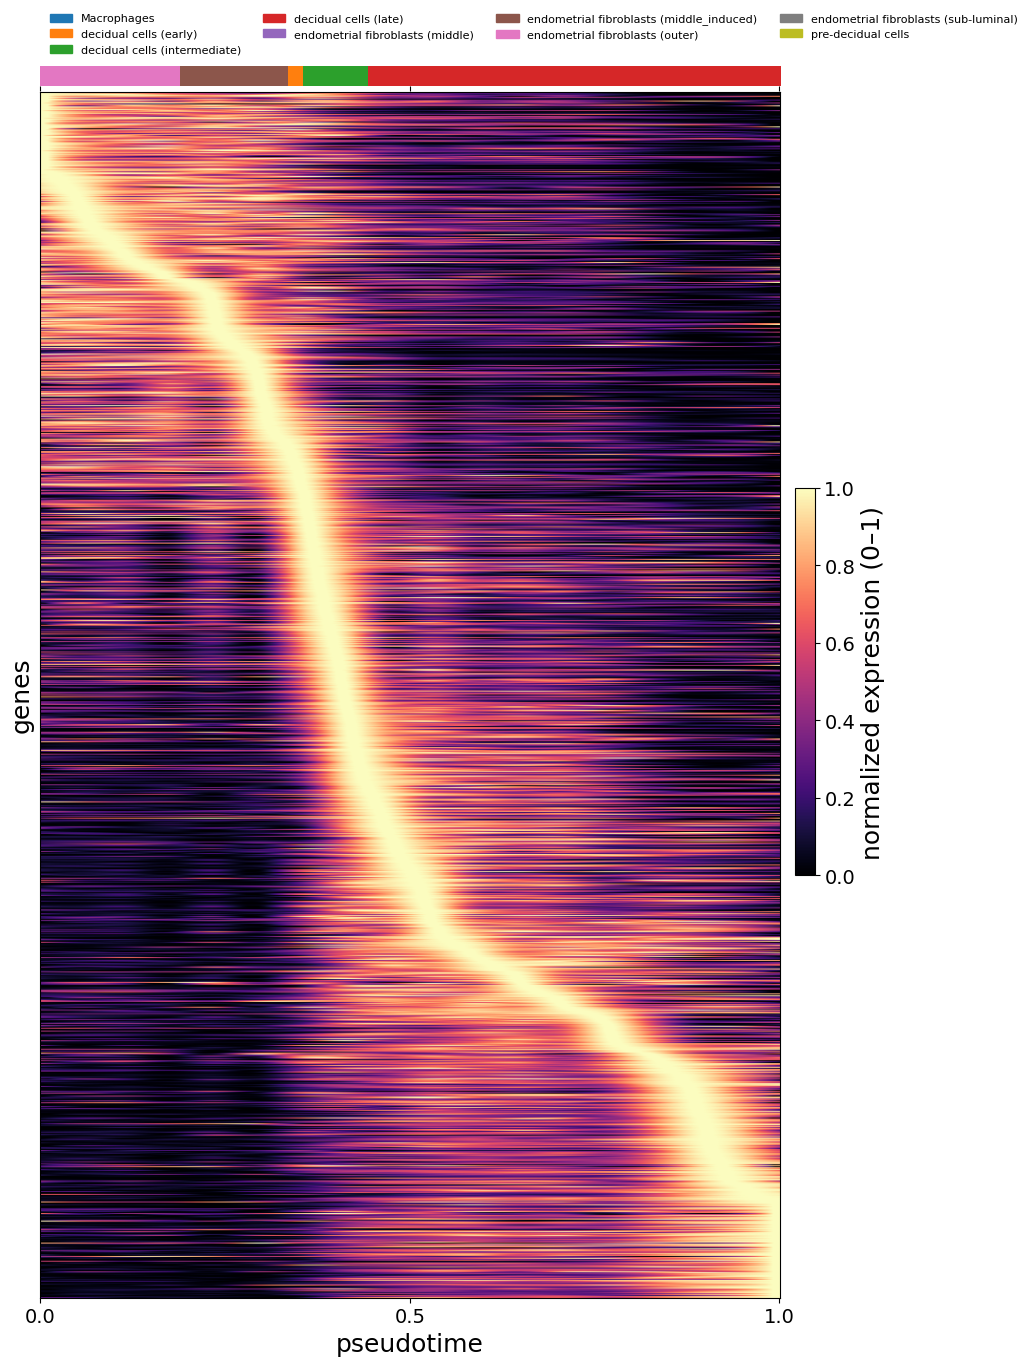

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# --- categorical cell-identity band along pt_grid ---
cell_pt  = adata.obs["dpt_pseudotime"].astype(float).values
cell_lab = adata.obs["cell_type_fine"].astype(str).values
ok = np.isfinite(cell_pt)
cell_pt, cell_lab = cell_pt[ok], cell_lab[ok]

# stable category -> integer code mapping
cats = list(pd.Categorical(adata.obs["cell_type_fine"]).categories)
cats = [c for c in cats if c in set(cell_lab)]          # keep only labels actually present
code = {c: i for i, c in enumerate(cats)}
lab_code = np.array([code[l] for l in cell_lab])

sortk = np.argsort(cell_pt)
pt_s, code_s = cell_pt[sortk], lab_code[sortk]
w = (pt_grid.max() - pt_grid.min()) / 50                # window half-width

band_codes = np.full(pt_grid.shape, -1)
for i, x0 in enumerate(pt_grid):
    lo = np.searchsorted(pt_s, x0 - w, "left")
    hi = np.searchsorted(pt_s, x0 + w, "right")
    if hi > lo:
        band_codes[i] = np.bincount(code_s[lo:hi]).argmax()   # majority label

# fill empty windows by nearest non-empty
if (band_codes < 0).any():
    idx = np.arange(len(band_codes)); good = band_codes >= 0
    band_codes = np.round(
        np.interp(idx, idx[good], band_codes[good])
    ).astype(int)

band = band_codes.reshape(1, -1)

# color per category (tab10/tab20 depending on count)
base = plt.cm.tab10 if len(cats) <= 10 else plt.cm.tab20
colors = [base(i % base.N) for i in range(len(cats))]
band_cmap = ListedColormap(colors)

# --- redraw ---
fig, (ax_band, ax_heat) = plt.subplots(
    2, 1, figsize=(10, 16), sharex=True,
    gridspec_kw={"height_ratios": [1, 60], "hspace": 0.01},
)

ax_band.imshow(band, aspect="auto", cmap=band_cmap,
               vmin=0, vmax=len(cats) - 1, interpolation="nearest")
ax_band.set_yticks([]); ax_band.set_xticks([])
for s in ax_band.spines.values():
    s.set_visible(False)
ax_band.legend(
    handles=[Patch(color=colors[i], label=c) for i, c in enumerate(cats)],
    loc="lower left", bbox_to_anchor=(0, 1.05),
    ncol=min(len(cats), 4), frameon=False, fontsize=8,
)

im = ax_heat.imshow(norm_epxr, aspect="auto", interpolation="bilinear",
                    cmap="magma", origin="upper")
ax_heat.set_xlabel("pseudotime"); ax_heat.set_ylabel("genes")
ax_heat.set_yticks([])
ax_heat.set_xticks([0, norm_epxr.shape[1] // 2, norm_epxr.shape[1] - 1])
ax_heat.set_xticklabels(["0.0", "0.5", "1.0"])

fig.colorbar(im, ax=[ax_band, ax_heat], label="normalized expression (0–1)",
             fraction=0.025, pad=0.02)
plt.savefig("./mouse_pseudotime_heatmap_fine.png", dpi=300, bbox_inches="tight")
plt.show()

In [17]:
adata_mouse_mi.obs['cell_type_coarse']

CTTTCAAAGGCCCACT             decidual cells
AATCGACGTTTCTTAC             decidual cells
CATAGACCAGTTAGAA             decidual cells
CAGCACGTCAAGGCTT             decidual cells
TCAGGTATCGCACGAC             decidual cells
                             ...           
ACTCCCATCGCCTCTA             decidual cells
CTACTATTCTGTGCTC    endometrial fibroblasts
AGCATCACAATACGCT    endometrial fibroblasts
GGTAGAGTCGCAAGAG    endometrial fibroblasts
CTGAGCGGTTCGGTTA    endometrial fibroblasts
Name: cell_type_coarse, Length: 15962, dtype: category
Categories (2, object): ['decidual cells', 'endometrial fibroblasts']

In [23]:
human_genes = (
    mi_genes.loc[mi_genes['top_10_pct_mi'].isin(['human', 'both'])]
    .index
    .dropna()
    .unique()
    .tolist()
)

missing = set(human_genes) - set(adata_human.var_names)
if missing:
    print(f"{len(missing)} genes not in adata_human.var_names, dropping: {sorted(missing)[:10]}...")
    human_genes = [g for g in human_genes if g in adata_human.var_names]

adata_human_mi = adata_human[:, human_genes].copy()

In [27]:
from pygam import LinearGAM, s

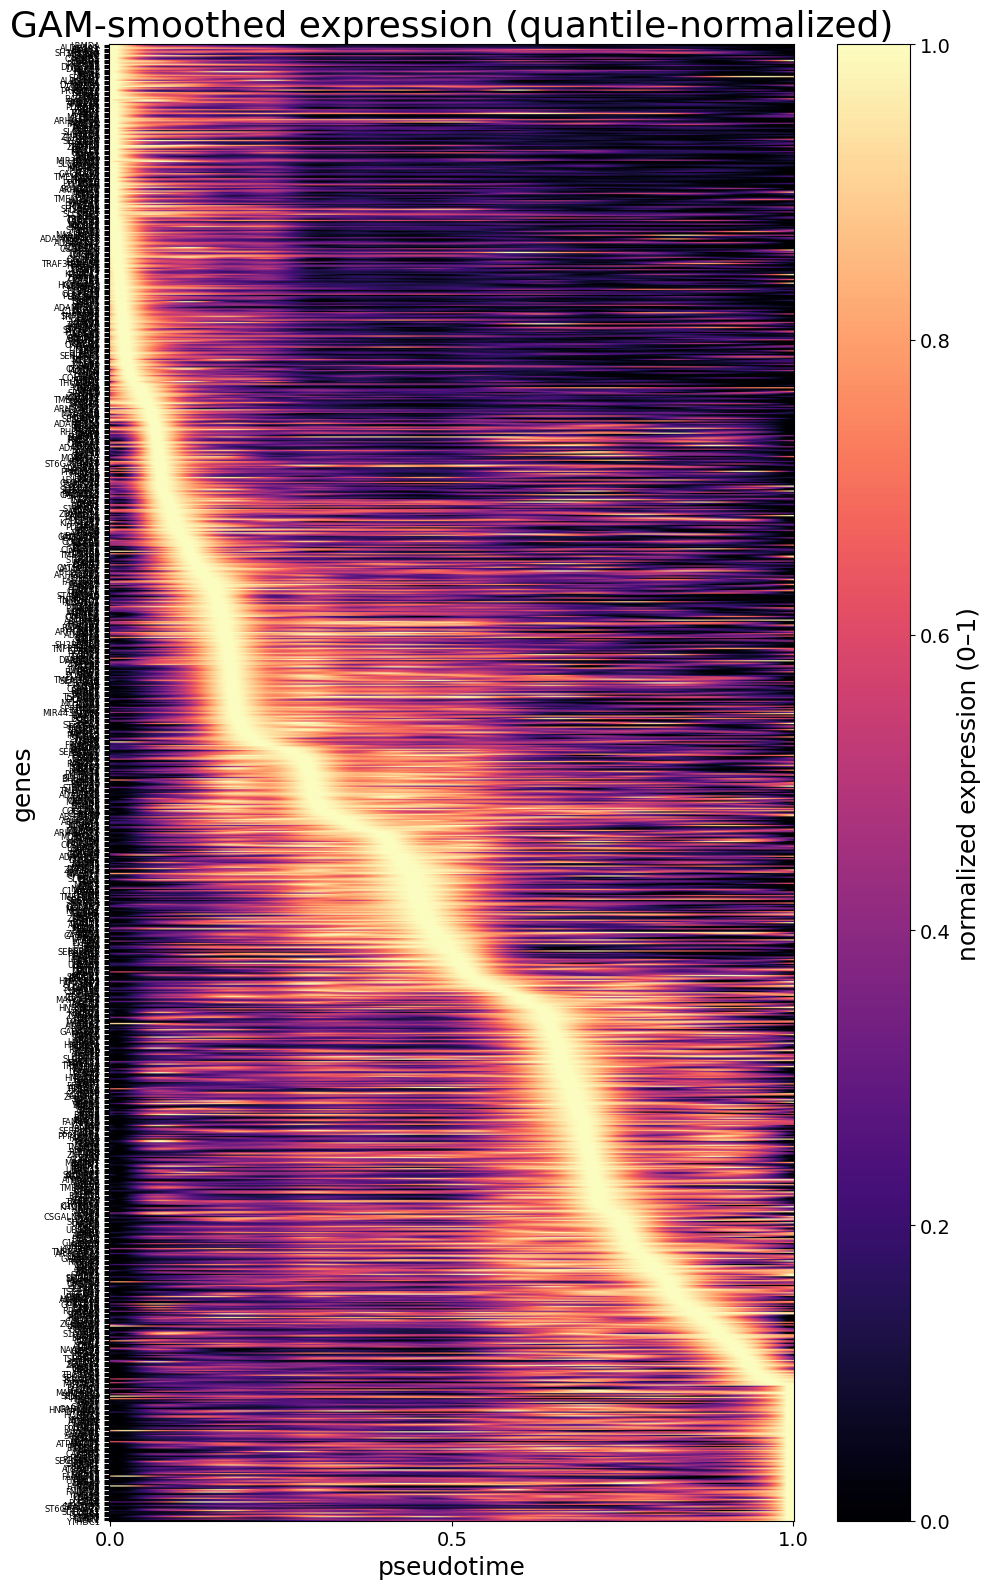

In [28]:
adata = adata_human_mi.copy()

# pull pseudotime + expression
pt = adata.obs["dpt_pseudotime"].astype(float).values
mask = np.isfinite(pt)
expr_df = sc.get.obs_df(adata[mask], keys=list(adata.var_names), layer="log1p")
expr_df["pseudotime"] = pt[mask]

pt_grid = np.linspace(expr_df["pseudotime"].min(), expr_df["pseudotime"].max(), 800)

# fit GAM for each gene
smoothed = {}
x = expr_df["pseudotime"].values
for gene in adata.var_names:
    y = expr_df[gene].values
    gam = LinearGAM(s(0, n_splines=20)).fit(x, y)
    smoothed[gene] = gam.predict(pt_grid)

heatmap_df = pd.DataFrame(smoothed, index=pt_grid).T  # genes by pseudotime grid

# quantile-normalize
low = heatmap_df.quantile(0.01, axis=1)
high = heatmap_df.quantile(0.99, axis=1)
robust = (
    heatmap_df
    .sub(low, axis=0)
    .div((high - low).replace(0, np.nan), axis=0)
    .clip(0, 1)
    .fillna(0)
)

# sort genes by peak pseudotime
peak_idx = robust.values.argmax(axis=1)
order = np.argsort(peak_idx)
robust = robust.iloc[order]

# plot arrays
norm_epxr = robust.values

# heatmap
plt.figure(figsize=(10, 16))
im = plt.imshow(
    norm_epxr,
    aspect="auto",
    interpolation="bilinear",
    cmap="magma",
    origin="upper"
)

plt.colorbar(im, label="normalized expression (0–1)")
plt.xlabel("pseudotime")
plt.ylabel("genes")
plt.title("GAM-smoothed expression (quantile-normalized)")

plt.yticks(range(len(robust)), robust.index, fontsize=6)
plt.xticks([0, int(norm_epxr.shape[1]/2), norm_epxr.shape[1]-1], ["0.0", "0.5", "1.0"])

plt.tight_layout()
plt.savefig("./mouse_pseudotime_heatmap.png", dpi=300,
            bbox_inches="tight")
plt.show()

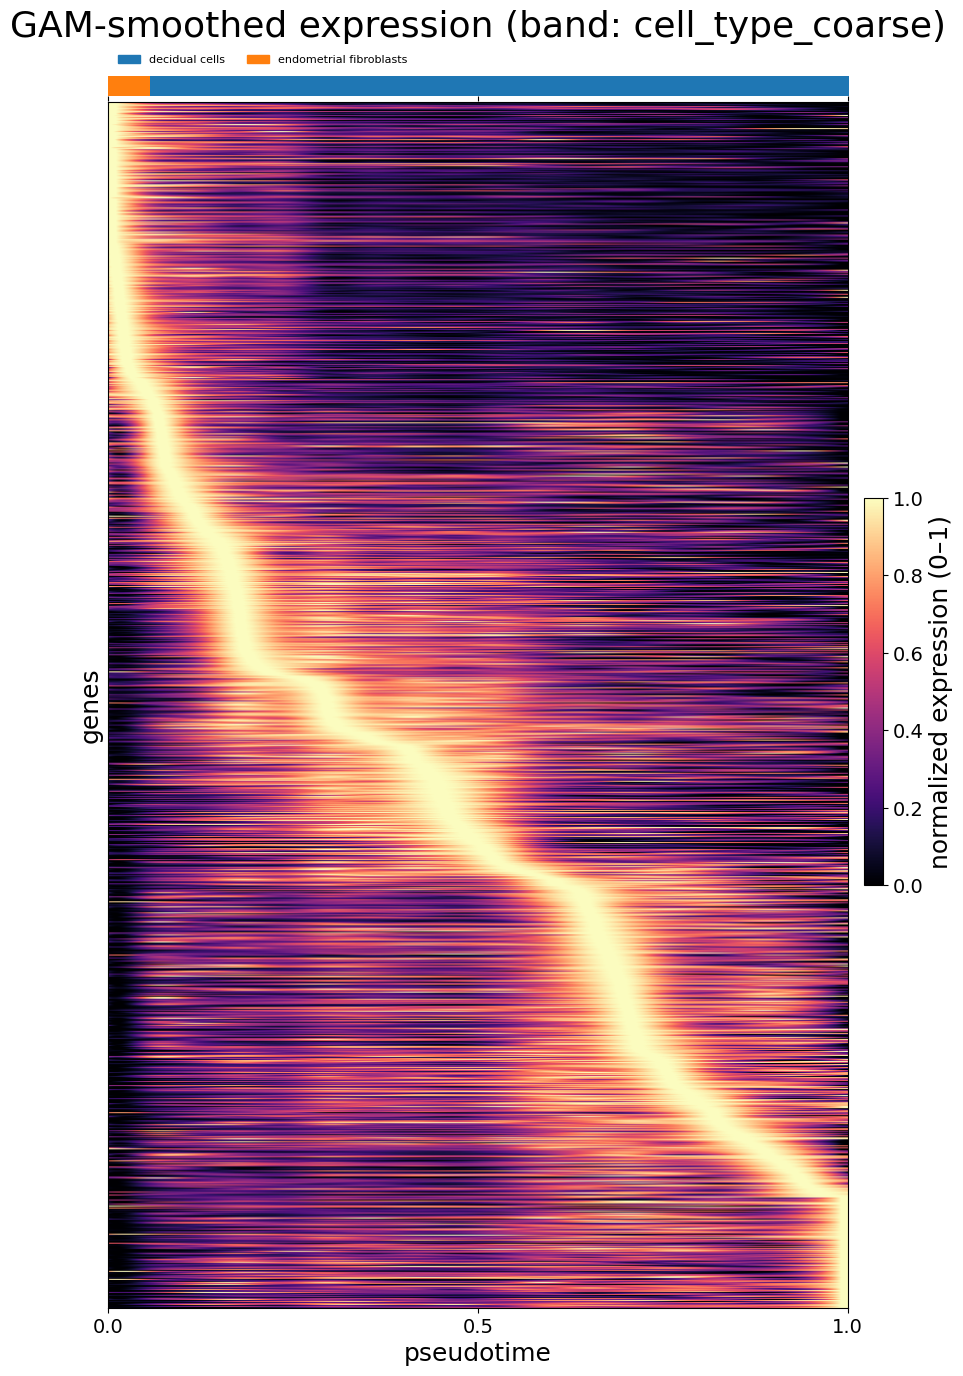

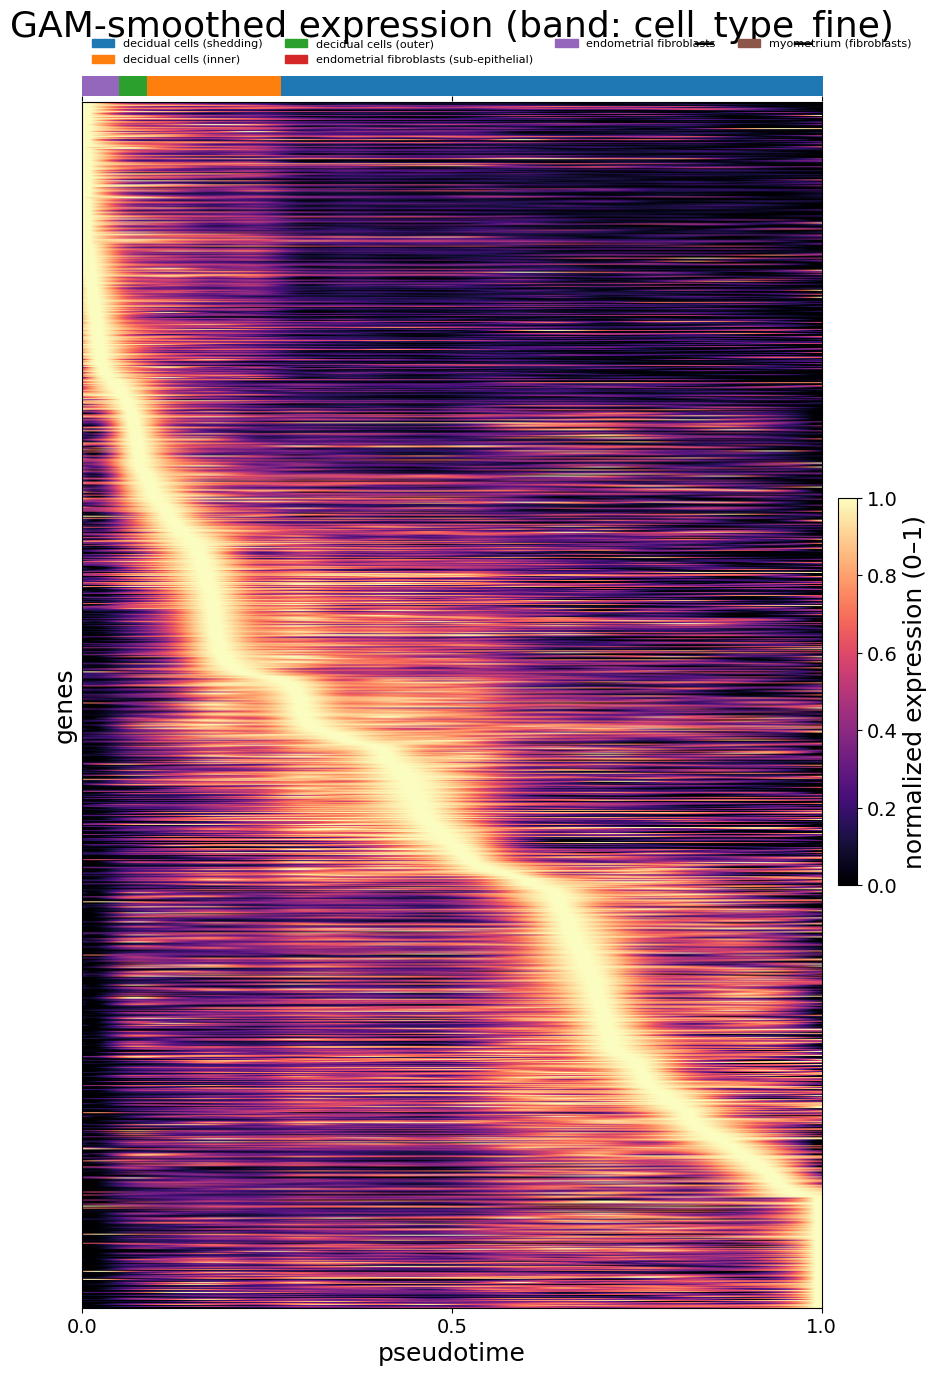

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

def plot_with_band(field, out_png, window_div=50, legend_ncol=None):
    # --- categorical cell-identity band along pt_grid ---
    cell_pt  = adata.obs["dpt_pseudotime"].astype(float).values
    cell_lab = adata.obs[field].astype(str).values
    ok = np.isfinite(cell_pt)
    cell_pt, cell_lab = cell_pt[ok], cell_lab[ok]

    cats = list(pd.Categorical(adata.obs[field]).categories)
    cats = [c for c in cats if c in set(cell_lab)]
    code = {c: i for i, c in enumerate(cats)}
    lab_code = np.array([code[l] for l in cell_lab])

    sortk = np.argsort(cell_pt)
    pt_s, code_s = cell_pt[sortk], lab_code[sortk]
    w = (pt_grid.max() - pt_grid.min()) / window_div

    band_codes = np.full(pt_grid.shape, -1)
    for i, x0 in enumerate(pt_grid):
        lo = np.searchsorted(pt_s, x0 - w, "left")
        hi = np.searchsorted(pt_s, x0 + w, "right")
        if hi > lo:
            band_codes[i] = np.bincount(code_s[lo:hi]).argmax()

    if (band_codes < 0).any():
        idx = np.arange(len(band_codes)); good = band_codes >= 0
        band_codes = np.round(np.interp(idx, idx[good], band_codes[good])).astype(int)

    band = band_codes.reshape(1, -1)
    base = plt.cm.tab10 if len(cats) <= 10 else plt.cm.tab20
    colors = [base(i % base.N) for i in range(len(cats))]
    band_cmap = ListedColormap(colors)

    # --- redraw (reuses norm_epxr / robust as-is) ---
    fig, (ax_band, ax_heat) = plt.subplots(
        2, 1, figsize=(10, 16), sharex=True,
        gridspec_kw={"height_ratios": [1, 60], "hspace": 0.01},
    )

    ax_band.imshow(band, aspect="auto", cmap=band_cmap,
                   vmin=0, vmax=len(cats) - 1, interpolation="nearest")
    ax_band.set_yticks([]); ax_band.set_xticks([])
    for spine in ax_band.spines.values():
        spine.set_visible(False)
    ax_band.legend(
        handles=[Patch(color=colors[i], label=c) for i, c in enumerate(cats)],
        loc="lower left", bbox_to_anchor=(0, 1.05),
        ncol=legend_ncol or min(len(cats), 4), frameon=False, fontsize=8,
    )

    im = ax_heat.imshow(norm_epxr, aspect="auto", interpolation="bilinear",
                        cmap="magma", origin="upper")
    ax_heat.set_xlabel("pseudotime"); ax_heat.set_ylabel("genes")
    ax_heat.set_yticks([])
    ax_heat.set_xticks([0, norm_epxr.shape[1] // 2, norm_epxr.shape[1] - 1])
    ax_heat.set_xticklabels(["0.0", "0.5", "1.0"])
    ax_band.set_title(f"GAM-smoothed expression (band: {field})", pad=28)

    fig.colorbar(im, ax=[ax_band, ax_heat], label="normalized expression (0–1)",
                 fraction=0.025, pad=0.02)
    plt.savefig(out_png, dpi=300, bbox_inches="tight")
    plt.show()

plot_with_band("cell_type_coarse", "./human_pseudotime_heatmap_coarse.png")
plot_with_band("cell_type_fine",   "./human_pseudotime_heatmap_fine.png")

In [31]:
adata_human_mi.obs['cell_type_fine'].value_counts()

cell_type_fine
endometrial fibroblasts                     14351
decidual cells (inner)                       9711
decidual cells (outer)                       8511
myometrium (fibroblasts)                     6273
endometrial fibroblasts (sub-epithelial)     4044
decidual cells (shedding)                    1866
Name: count, dtype: int64